# Decision Trees with LEGO - DEV C

This notebook contains the developer C part of the main notebook.

### Imports

In [62]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import src.data as data
import src.plots as plots
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from sklearn.model_selection import GridSearchCV

Constants

In [63]:
SEED = [0, 42, 123, 456, 789]
N = 300
NOISE = 0.15
#MAX_DEPTH = 3
TEST_SIZE = 0.3
CRITERION = "entropy"

Experiment 3:  Attempted improvement

**Prediction:**

-The Accuracy for the Training data will be optimitic, the model that was selected based on its performance with that data. There is the risk that it, by chance, classified some of the noise correctly, inflating its Accuracy.

-The Accuracy for the Test data will be better than in Exp. 2., due to its optimized hyperparameter, but still lower than in Exp. 1., due to the noise.

seed: 0
{'max_depth': 4, 'min_samples_leaf': 1}
training Accuracy: 0.861904761904762
test Accuracy:
Accuracy (stickers): 0.8
Accuracy (truth): 0.9666666666666667
CV metrics:
Best CV score (accuracy): 0.8238095238095238


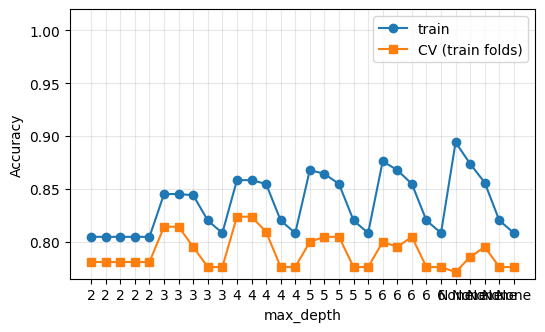

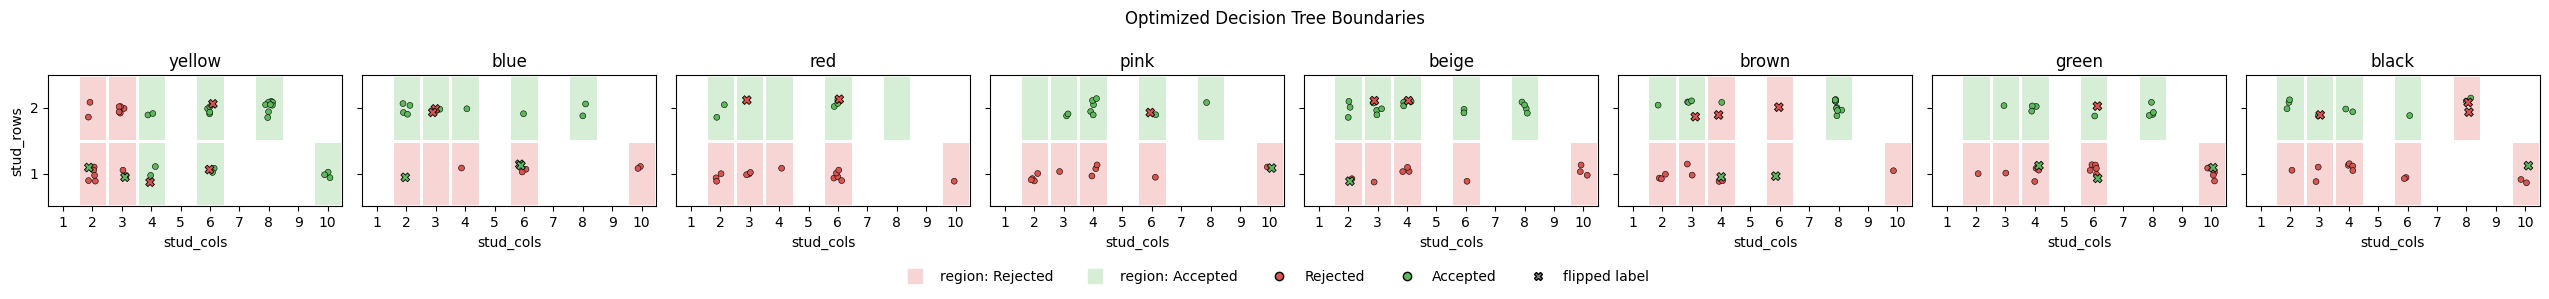

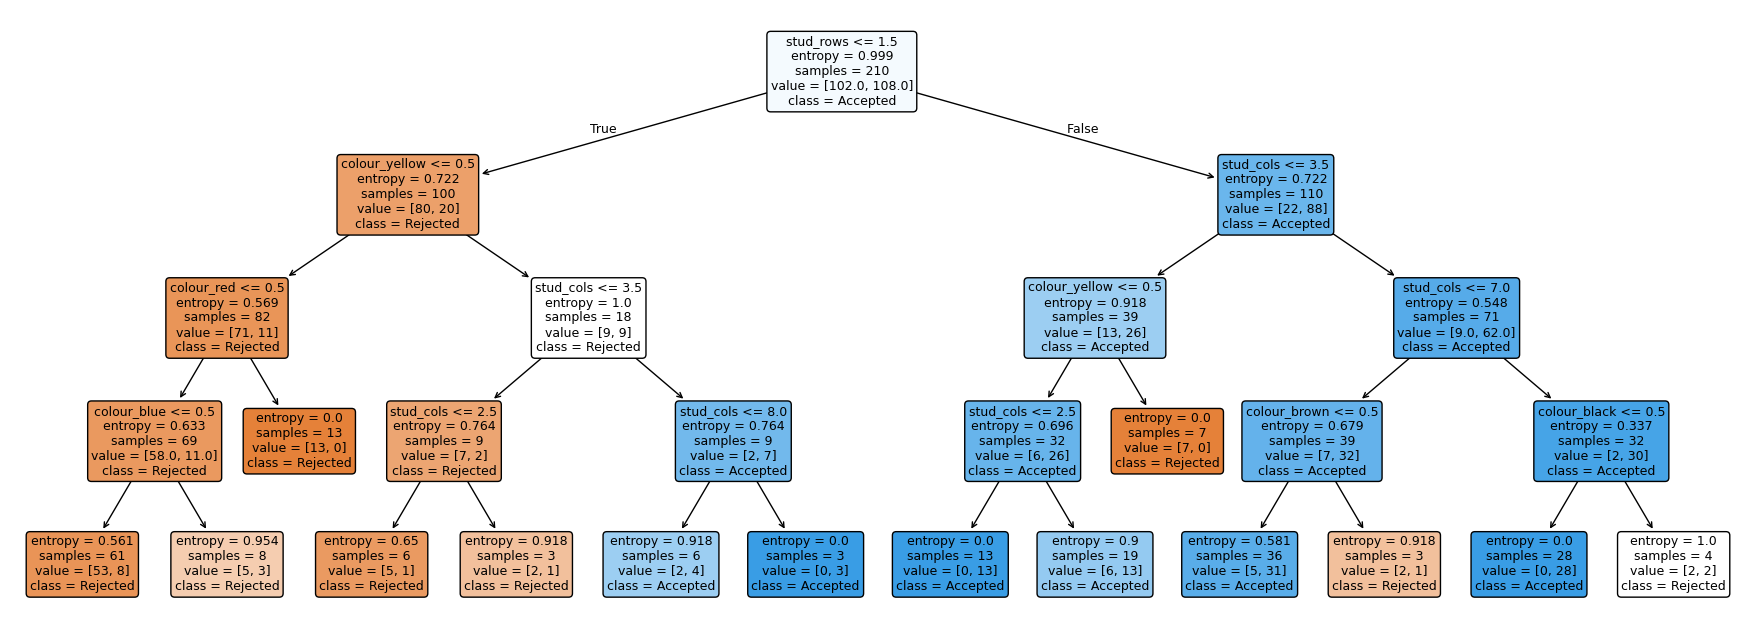

seed: 42
{'max_depth': 2, 'min_samples_leaf': 1}
training Accuracy: 0.8523809523809524
test Accuracy:
Accuracy (stickers): 0.7777777777777778
Accuracy (truth): 0.9666666666666667
CV metrics:
Best CV score (accuracy): 0.8523809523809524


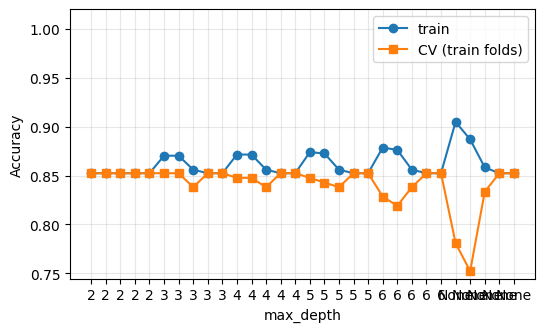

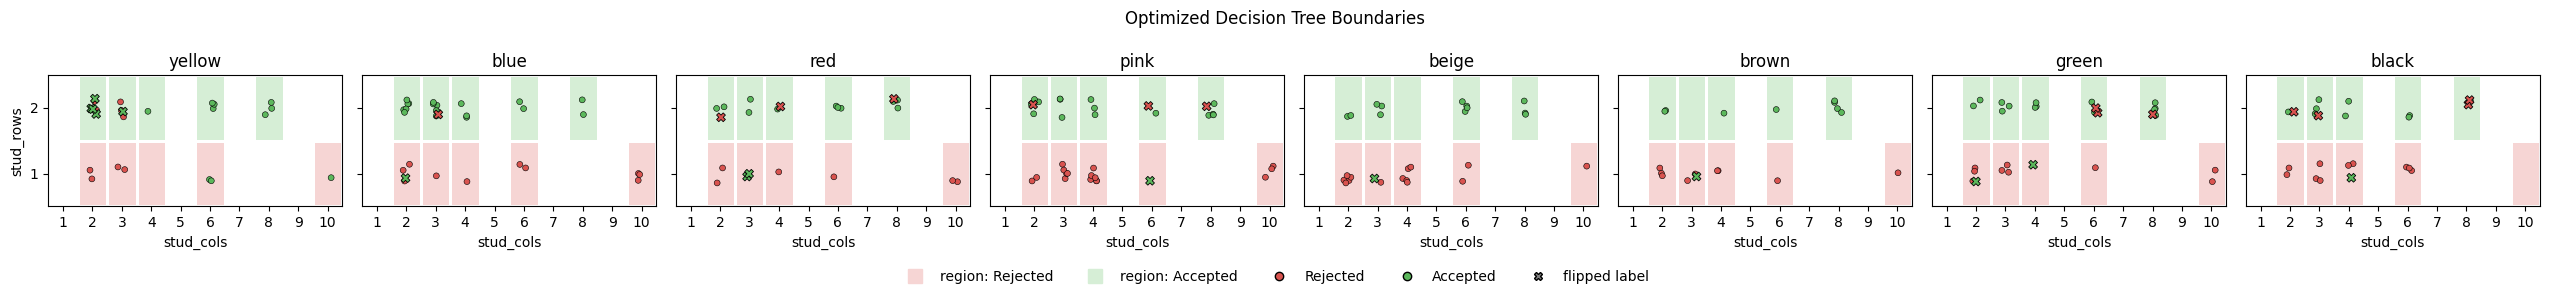

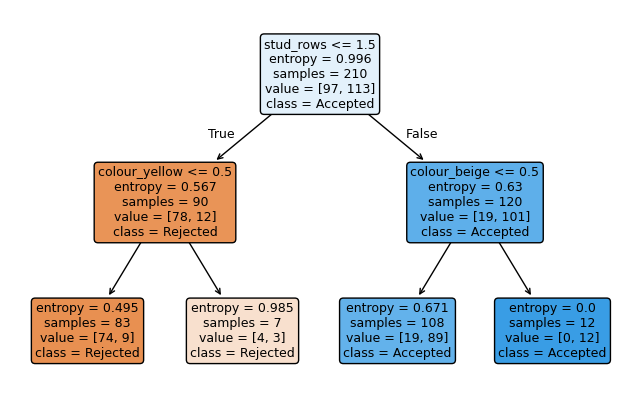

seed: 123
{'max_depth': 5, 'min_samples_leaf': 1}
training Accuracy: 0.8666666666666667
test Accuracy:
Accuracy (stickers): 0.8666666666666667
Accuracy (truth): 0.9777777777777777
CV metrics:
Best CV score (accuracy): 0.8428571428571429


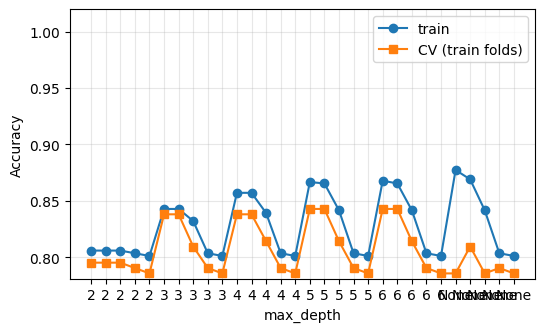

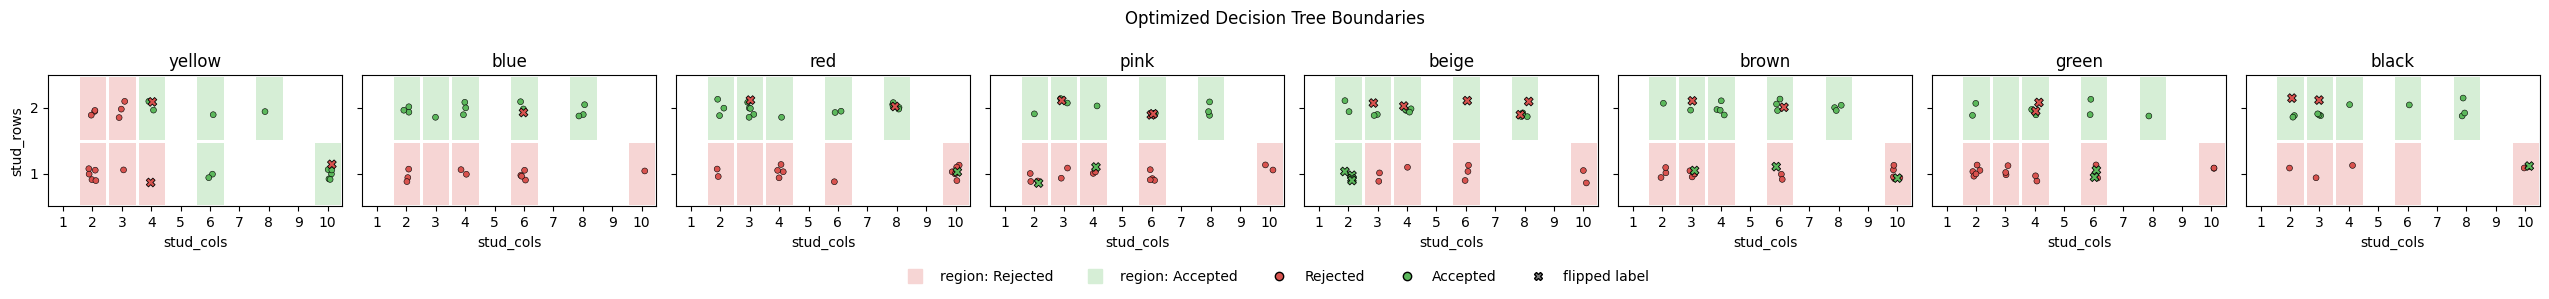

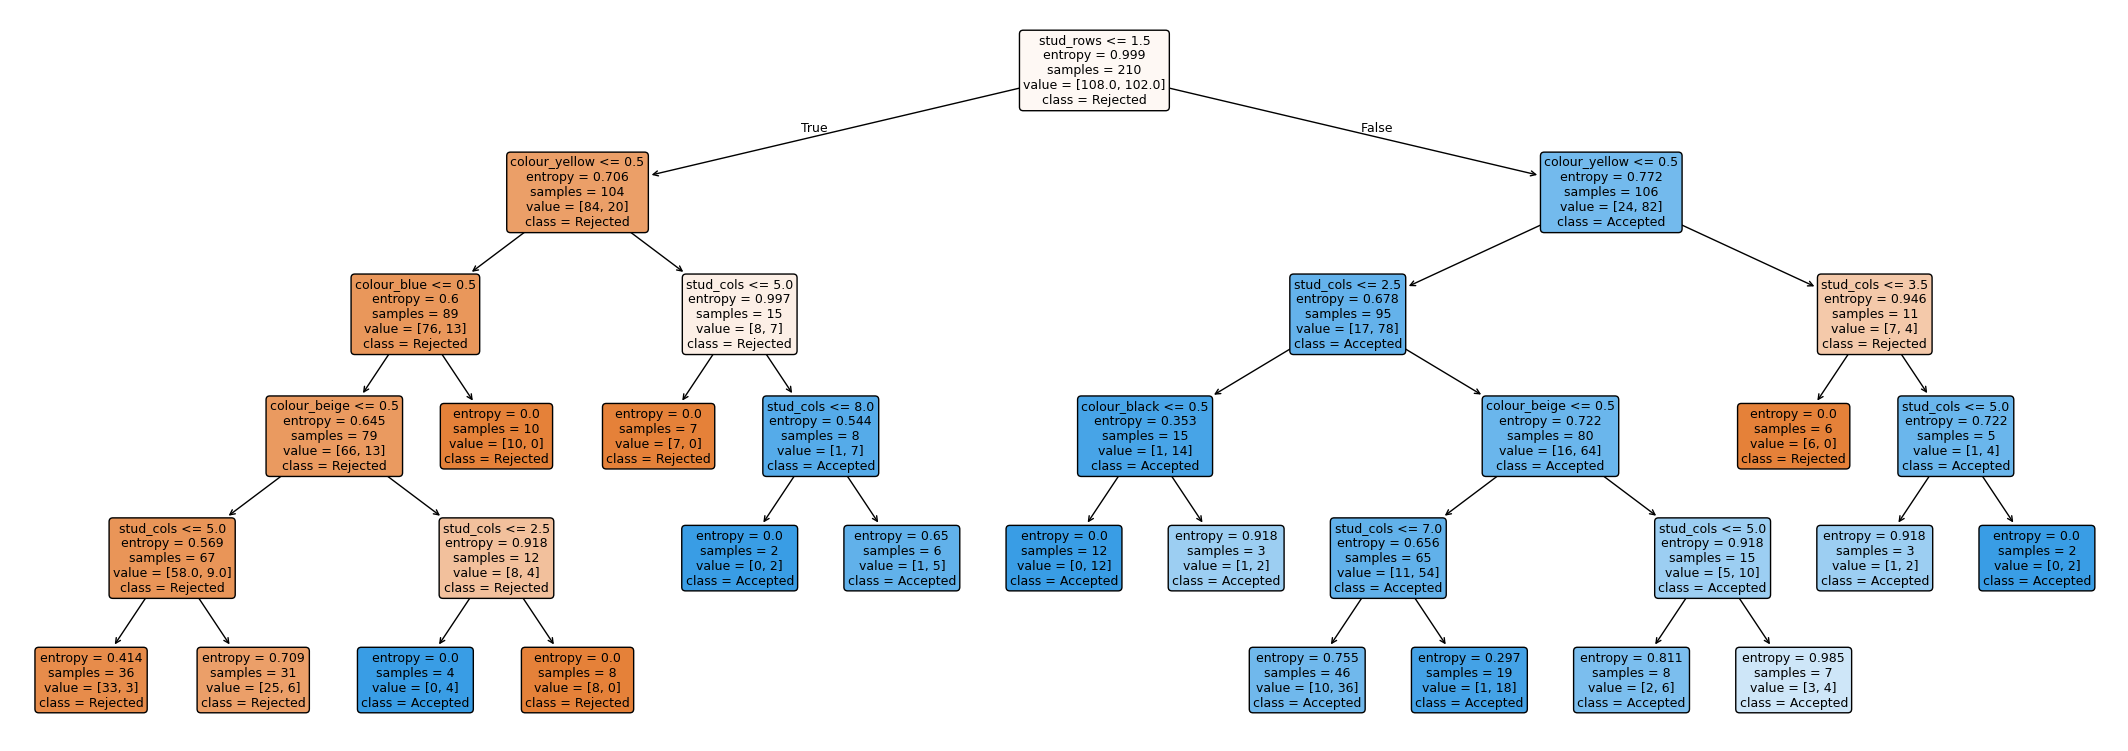

seed: 456
{'max_depth': 2, 'min_samples_leaf': 1}
training Accuracy: 0.8380952380952381
test Accuracy:
Accuracy (stickers): 0.7888888888888889
Accuracy (truth): 0.9555555555555556
CV metrics:
Best CV score (accuracy): 0.8380952380952381


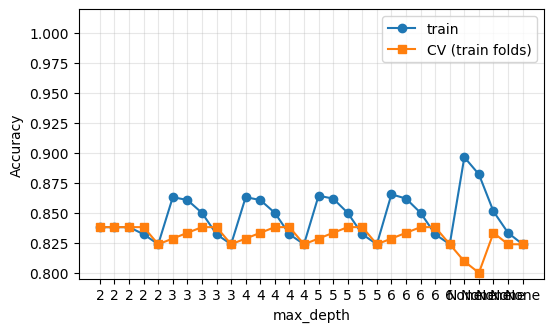

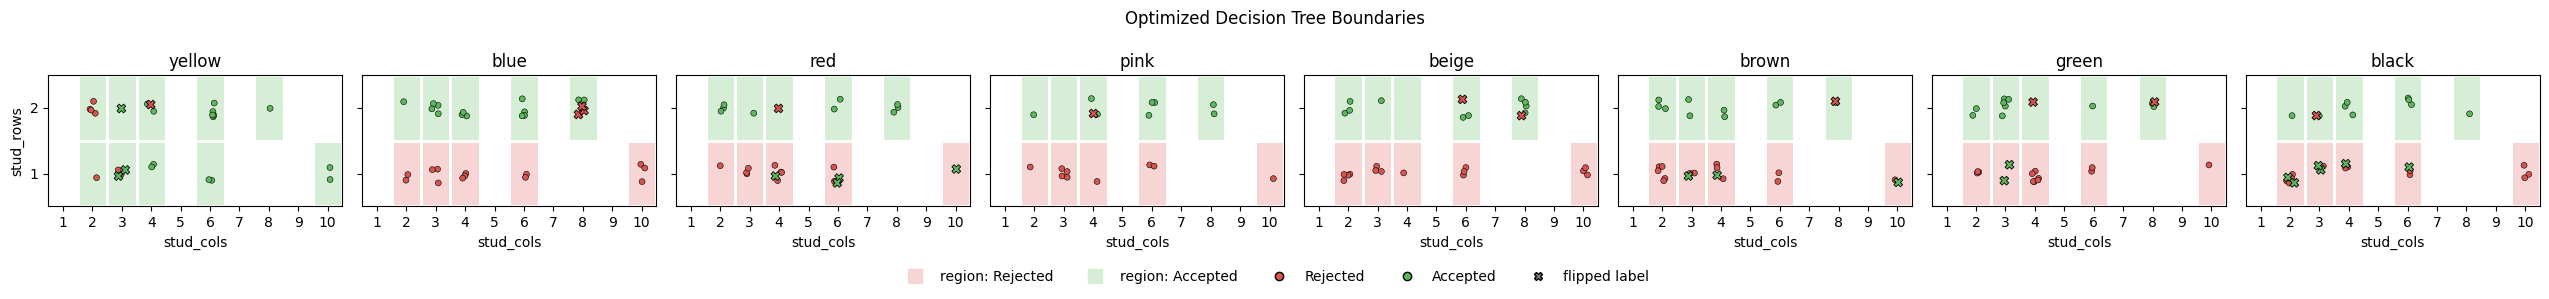

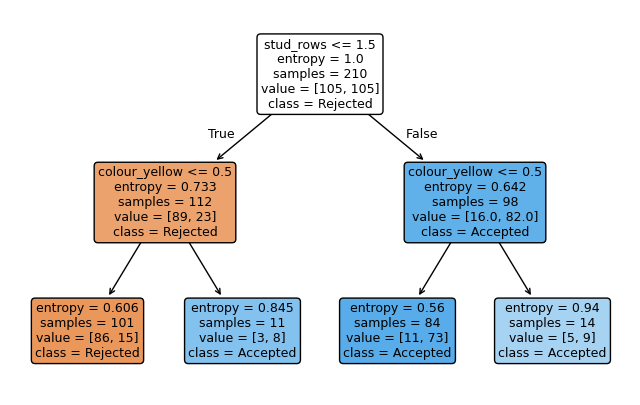

seed: 789
{'max_depth': 3, 'min_samples_leaf': 1}
training Accuracy: 0.8476190476190476
test Accuracy:
Accuracy (stickers): 0.8555555555555555
Accuracy (truth): 1.0
CV metrics:
Best CV score (accuracy): 0.8333333333333333


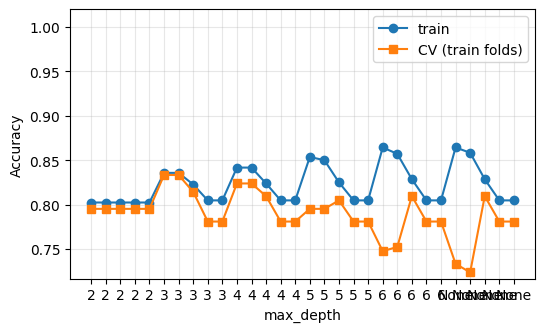

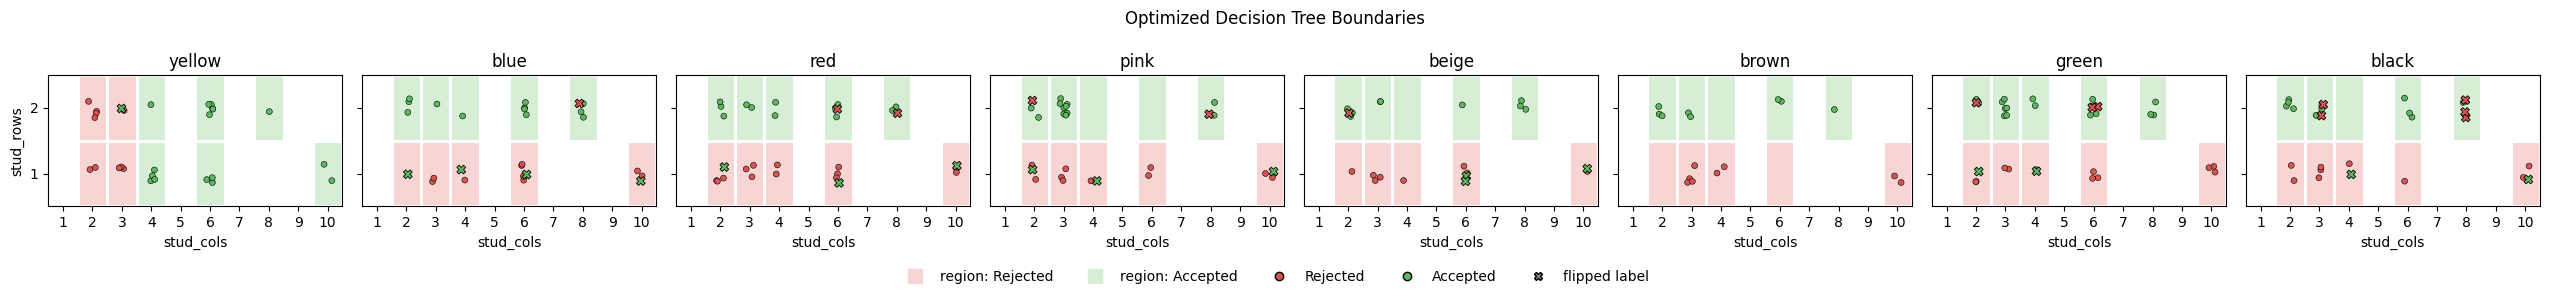

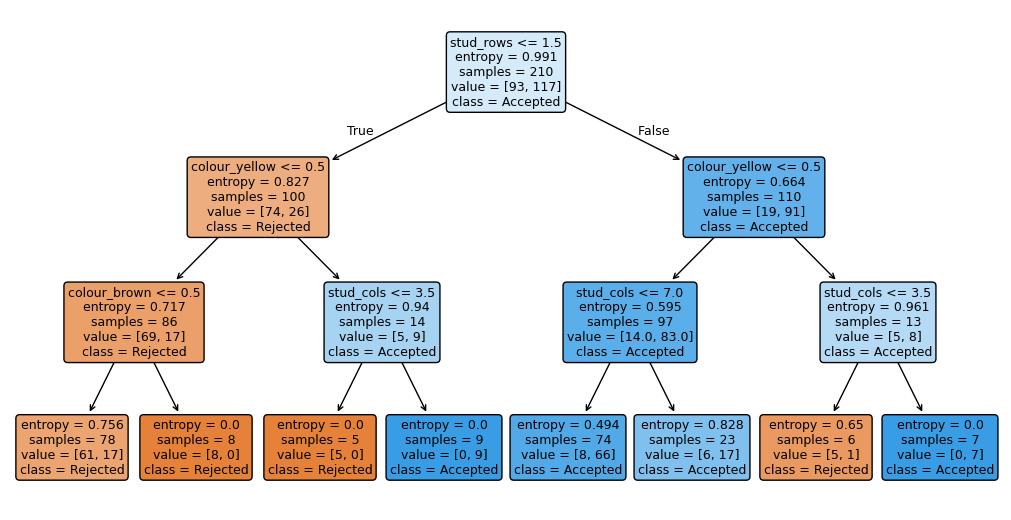

Test Accuracy (stickers) over 5 seeds:
 Mean: 0.818
 Std: 0.036
Accuracy (truth) over 5 seeds:
 Mean: 0.973
 Std: 0.015


In [ ]:
accuracy_sticker_results= []
accuracy_truth_results = []
for s in SEED:

    df = data.make_data(n=N, noise=NOISE, seed=s)
    train_df, test_df = train_test_split(df, 
                                        test_size=TEST_SIZE, 
                                        stratify=df["accepted_true"], 
                                        random_state=s
    )

    enc = data.make_encoder()
    X_train = enc.fit_transform(train_df[data.FEATURES])
    y_train = train_df[data.TARGET]
    X_test  = enc.transform(test_df[data.FEATURES])
    y_test  = test_df[data.TARGET]
    names = list(enc.get_feature_names_out())

    parameters = {
        "max_depth": [2,3,4,5,6, None],
        "min_samples_leaf": [1,2,5,8,10],
    }
    dt = DecisionTreeClassifier(criterion=CRITERION, random_state=s)
    gs = GridSearchCV(dt, parameters, refit=True, scoring='accuracy', cv=5, return_train_score=True)
    gs.fit(X_train, y_train)

    y_pred =gs.predict(X_test)

    print(f"seed: {s}")
    print(gs.best_params_)
    print(f"training Accuracy: {accuracy_score(train_df[data.TARGET], gs.predict(X_train))}")

    print("test Accuracy:")
    acc_stk = accuracy_score(test_df[data.TARGET], y_pred)
    acc_tru = accuracy_score(test_df['accepted_true'], y_pred)
    accuracy_sticker_results.append(acc_stk)
    accuracy_truth_results.append(acc_tru)
    print(f"Accuracy (stickers): {acc_stk}")
    print(f"Accuracy (truth): {acc_tru}")

    # Cross-validation performance metrics (mean CV score for the best estimator)
    print("CV metrics:")
    print(f"Best CV score (accuracy): {gs.best_score_}")

    # Extract the tuned parameter values and scores from GridSearchCV results
    results = gs.cv_results_
    param_name = list(parameters.keys())[0]  # e.g., 'max_depth'
    values = results[f"param_{param_name}"]
    train_scores = results["mean_train_score"] if "mean_train_score" in results else None
    cv_scores = results["mean_test_score"]

    # Plotting
    plots.plot_curves(values=values, train_scores=train_scores, cv_scores=cv_scores, xlabel=param_name, ylabel="Accuracy")
    plots.plot_regions(gs.best_estimator_, enc, train_df, title="Optimized Decision Tree Boundaries")
    plots.plot_tree(gs.best_estimator_, enc)
    plt.show()

print(f"Test Accuracy (stickers) over {len(SEED)} seeds:\n Mean: {np.mean(accuracy_sticker_results):.3f}\n Std: {np.std(accuracy_sticker_results):.3f}")
print(f"Test Accuracy (truth) over {len(SEED)} seeds:\n Mean: {np.mean(accuracy_truth_results):.3f}\n Std: {np.std(accuracy_truth_results):.3f}")

**Conclusion**

In Exp. 2., the average test accuracy against stickers and against the truth is 0.794 (std 0.042) and 0.916 (std 0.044) respectively, but now, with its hyperparameters optimized, it gets an accuracy against stickers of 0.818 (std 0.036), right at the ceiling, and against truth of 0.973 (std 0.015). As the difference between the test accuracy against the truth surpasses the standard deviation of each, though the the test accuracy against stickers does not, the difference is considered statistically significant and so, it can be said that these results show an improvement over Exp. 2.,confirming my prediction.